# Detecting AI-generated video from its frequency content

Run the cells one at a time. Every clip below is from the **test split**: never used for training or model selection.

In [1]:
import os, sys, joblib
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.config import CLIPS, FPS, N_FRAMES, MODELS, RESULTS, UNSEEN
from src.data.video_io import read_frames
from src.features.spatial import power_spectrum, radial_spectrum, to_luma
from src.features.temporal import clip_features
from src.features.pixel_baseline import clip_pixel_features
from src.models import data as D
%matplotlib inline

df = D.clean_table()                                               # stored features of every clip
test = df[(df.split == "test") & ~df.aug.astype(bool)]             # the 267 held-out test clips
real = test.generator == "real"
sets = {"seen generators": ~test.generator.isin(UNSEEN),
        "ModelScope (unseen)": real | (test.generator == "modelscope"),
        "Wan2.1 (unseen)": real | (test.generator == "wan")}

def auroc_table(models):
    # AUROC of each (label, model_file) on each test set
    out = {}
    for set_name, mask in sets.items():
        t = test[mask]
        for label, model_file in models:
            m = joblib.load(MODELS / f"{model_file}.joblib")
            p = m["model"].predict_proba(np.nan_to_num(t[m["cols"]].to_numpy(np.float32)))[:, 1]
            out[(set_name, label)] = roc_auc_score(t.label, p)
    return pd.Series(out).unstack()[[label for label, _ in models]].round(3)

## 1. A real clip and a generated clip

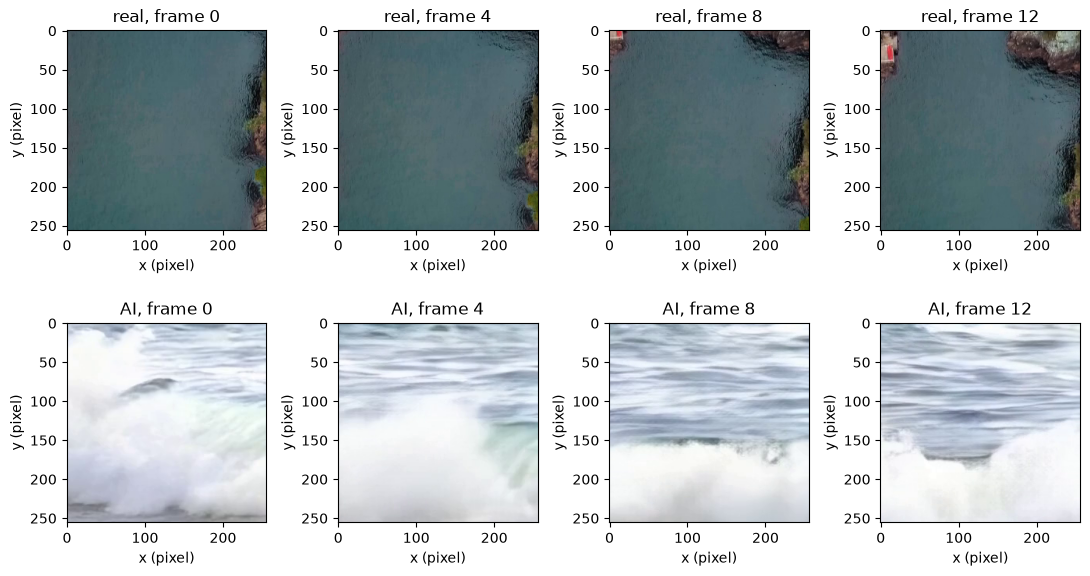

In [2]:
REAL, FAKE = "real_3121923", "ltx_0001"          # two held-out test clips
clips = {"real": read_frames(CLIPS / f"{REAL}.mp4", N_FRAMES, FPS),
         "AI":   read_frames(CLIPS / f"{FAKE}.mp4", N_FRAMES, FPS)}      # each: 14 frames of 256 x 256

fig, ax = plt.subplots(2, 4, figsize=(11, 6))
for r, (name, frames) in enumerate(clips.items()):
    for c, i in enumerate((0, 4, 8, 12)):
        ax[r, c].imshow(frames[i]); ax[r, c].set_title(f"{name}, frame {i}")
        ax[r, c].set_xlabel("x (pixel)"); ax[r, c].set_ylabel("y (pixel)")
plt.tight_layout()

## 2. Their spectra, extracted live

Grey frame -> 2-D FFT -> log power (centre = coarse structure, edge = fine detail) -> average over rings = **radial curve**.

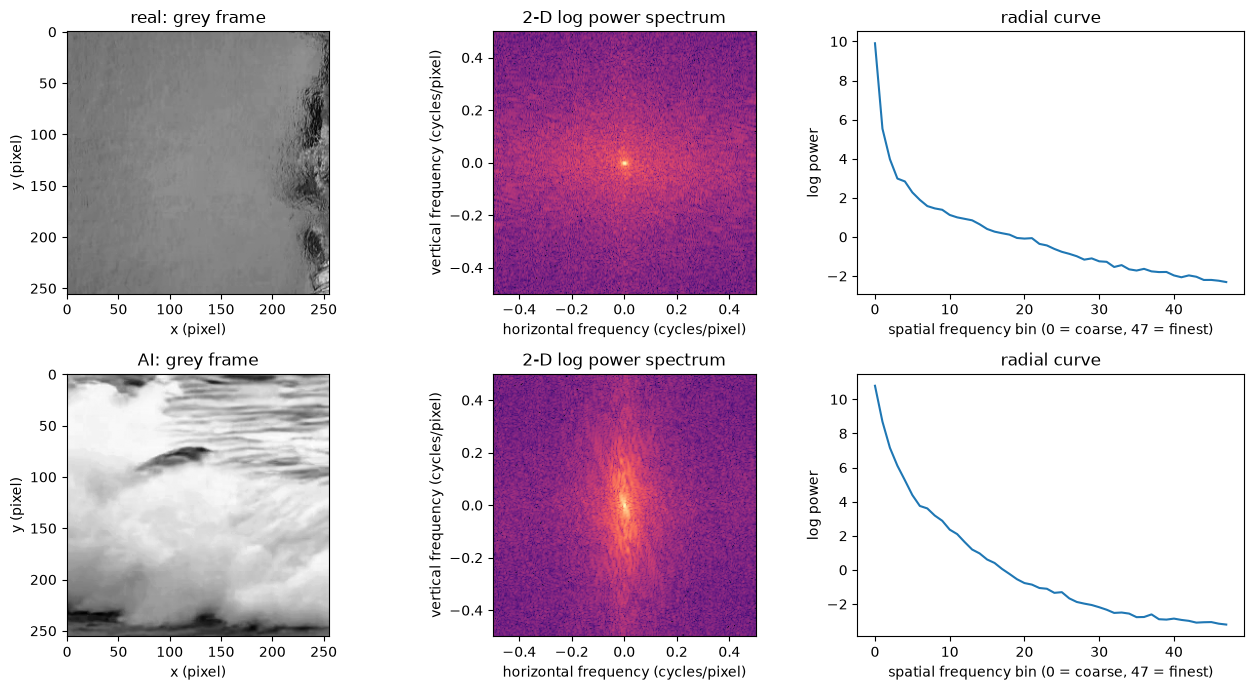

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
for r, (name, frames) in enumerate(clips.items()):
    gray = to_luma(frames[0])
    ax[r, 0].imshow(gray, cmap="gray")
    ax[r, 0].set(title=f"{name}: grey frame", xlabel="x (pixel)", ylabel="y (pixel)")
    ax[r, 1].imshow(np.log(power_spectrum(gray) + 1e-8), cmap="magma", extent=[-0.5, 0.5, -0.5, 0.5])
    ax[r, 1].set(title="2-D log power spectrum", xlabel="horizontal frequency (cycles/pixel)", ylabel="vertical frequency (cycles/pixel)")
    ax[r, 2].plot(radial_spectrum(gray))
    ax[r, 2].set(title="radial curve", xlabel="spatial frequency bin (0 = coarse, 47 = finest)", ylabel="log power")
plt.tight_layout()

## 3. Temporal features: how the spectrum changes from frame to frame

The radial curve is computed for each of the 14 frames. The distance between two consecutive curves is the **spectral drift**.
The temporal features are statistics of this drift (mean, spread, per frequency band, ...) plus 5 noise-residual features: 37 numbers per clip.
Camera footage and generated video fluctuate differently from frame to frame.

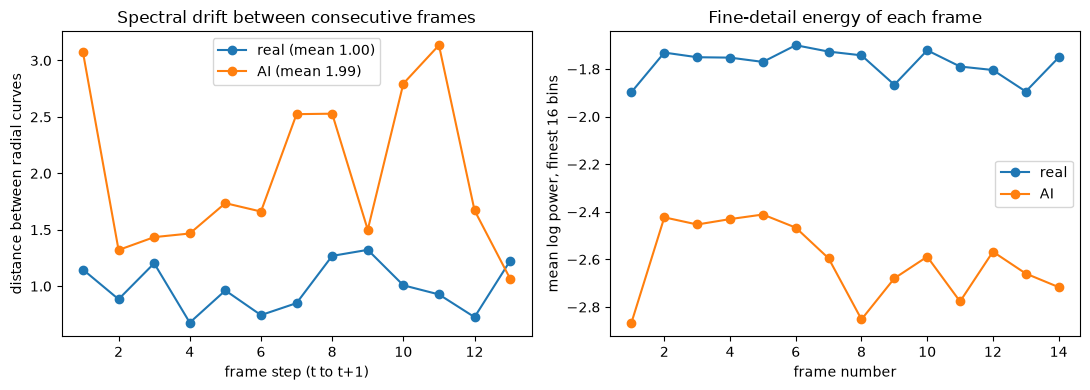

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, frames in clips.items():
    curves = np.stack([radial_spectrum(to_luma(f)) for f in frames])         # 14 frames x 48 frequency bins
    drift = np.linalg.norm(np.diff(curves, axis=0), axis=1)                  # distance between consecutive frames
    ax[0].plot(range(1, 14), drift, "o-", label=f"{name} (mean {drift.mean():.2f})")
    ax[1].plot(range(1, 15), curves[:, 32:].mean(axis=1), "o-", label=name)  # finest third of the frequencies
ax[0].set(title="Spectral drift between consecutive frames", xlabel="frame step (t to t+1)", ylabel="distance between radial curves")
ax[1].set(title="Fine-detail energy of each frame", xlabel="frame number", ylabel="mean log power, finest 16 bins")
for a in ax: a.legend()
plt.tight_layout()

The same two features for all 267 held-out test clips, one box per video source (stored features).
A single feature overlaps heavily between real and generated clips (the two clips above are not typical); the models combine all 37 temporal features.

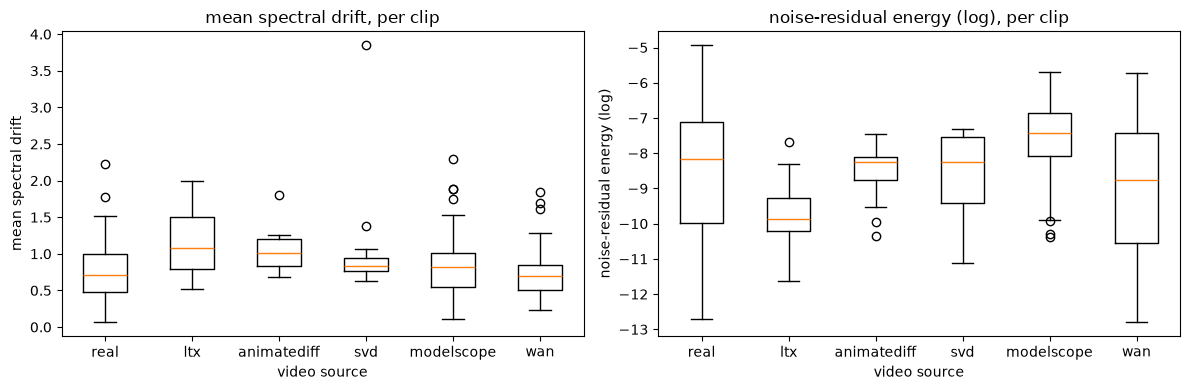

In [5]:
sources = ["real", "ltx", "animatediff", "svd", "modelscope", "wan"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, column, label in [(ax[0], "drift_l2_mean", "mean spectral drift"), (ax[1], "rt_energy", "noise-residual energy (log)")]:
    a.boxplot([test[test.generator == g][column] for g in sources], tick_labels=sources)
    a.set(title=f"{label}, per clip", xlabel="video source", ylabel=label)
plt.tight_layout()

Do the temporal features carry information on their own? Same trained models, same held-out clips, different feature sets.

                     spatial only  temporal only   both
ModelScope (unseen)         0.796          0.724  0.792
Wan2.1 (unseen)             0.699          0.680  0.677
seen generators             0.944          0.933  0.960


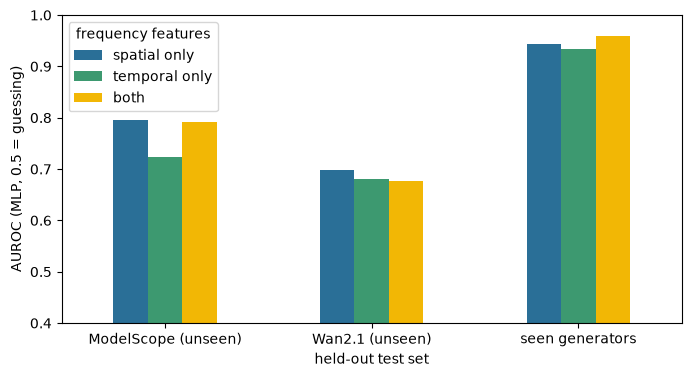

In [6]:
by_set = auroc_table([("spatial only", "mlp_spatial"), ("temporal only", "mlp_temporal"), ("both", "mlp_all")])
print(by_set.to_string())
ax = by_set.plot.bar(rot=0, ylim=(0.4, 1), color=["#2a6f97", "#3d9970", "#f2b705"], figsize=(8, 4))
ax.set(xlabel="held-out test set", ylabel="AUROC (MLP, 0.5 = guessing)"); ax.legend(title="frequency features");

Is it really the **order** of the frames? Shuffling the 14 frames of every test clip destroys the frame-to-frame changes but keeps each frame's own spectrum.
(Stored result of `python -m src.eval.temporal_order`, seen generators.)

               auroc_original  auroc_variant  change
spatial only            0.944          0.944   0.000
temporal only           0.933          0.795  -0.138
both                    0.960          0.943  -0.017


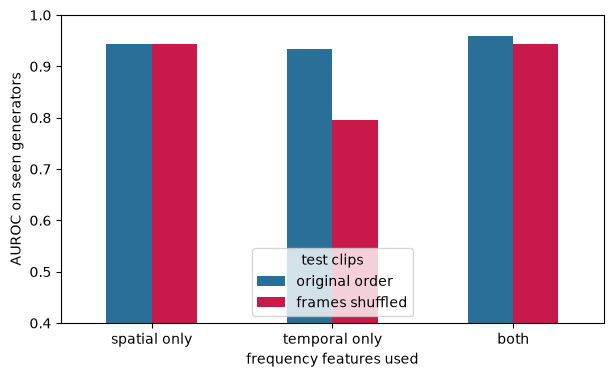

In [7]:
order = pd.read_csv(RESULTS / "temporal_order.csv")
order = order[(order.set == "seen") & (order.variant == "shuffled")].set_index("model").loc[["mlp_spatial", "mlp_temporal", "mlp_all"]]
order.index = ["spatial only", "temporal only", "both"]
print(order[["auroc_original", "auroc_variant", "change"]].to_string())
ax = order[["auroc_original", "auroc_variant"]].rename(columns={"auroc_original": "original order", "auroc_variant": "frames shuffled"}).plot.bar(
    rot=0, ylim=(0.4, 1), color=["#2a6f97", "#c9184a"], figsize=(7, 4))
ax.set(xlabel="frequency features used", ylabel="AUROC on seen generators"); ax.legend(title="test clips", loc="lower center");

## 4. From each clip to a verdict

Features of each clip: frequency features (fine detail + change over time) and pixel features (the control).
Then each model gives the probability that the clip is AI-made (true answers: the first clip is real, the second is AI).

In [8]:
stored_all = D.clean_table().set_index("clip_id")
models = [("pixel only", "mlp_pixel"), ("frequency only", "mlp_all"), ("combined", "mlp_fusion")]

for name, clip_id in [("real", REAL), ("AI", FAKE)]:
    feats, _ = clip_features(clips[name])
    n_freq = len(feats)
    feats.update(clip_pixel_features(clips[name]))
    diff = max(abs(stored_all.loc[clip_id, k] - feats[k]) for k in feats)       # live vs stored features
    print(f"{name} clip {clip_id}: {n_freq} frequency + {len(feats) - n_freq} pixel features; live vs stored difference {diff}")

    one = pd.DataFrame([feats])
    for model_name, model_file in models:
        m = joblib.load(MODELS / f"{model_file}.joblib")
        p = m["model"].predict_proba(np.nan_to_num(one[m["cols"]].to_numpy(np.float32)))[0, 1]
        print(f"   {model_name:15s} P(AI) = {p:.3f}  ->  {'AI' if p >= 0.5 else 'real'}")

real clip real_3121923: 263 frequency + 74 pixel features; live vs stored difference 0.0
   pixel only      P(AI) = 0.899  ->  AI
   frequency only  P(AI) = 0.024  ->  real
   combined        P(AI) = 0.670  ->  AI


AI clip ltx_0001: 263 frequency + 74 pixel features; live vs stored difference 0.0
   pixel only      P(AI) = 0.897  ->  AI
   frequency only  P(AI) = 0.997  ->  AI
   combined        P(AI) = 0.993  ->  AI


## 5. Pixel-only vs frequency-only vs combined, on the same held-out clips

The same 267 test clips, the same trained models, three feature sets (the stored features of these clips; step 4 showed that live extraction gives identical values). AUROC: 1.0 = perfect, 0.5 = guessing.

                     pixel  frequency  combined
ModelScope (unseen)  0.611      0.792     0.738
Wan2.1 (unseen)      0.821      0.677     0.811
seen generators      0.881      0.960     0.976


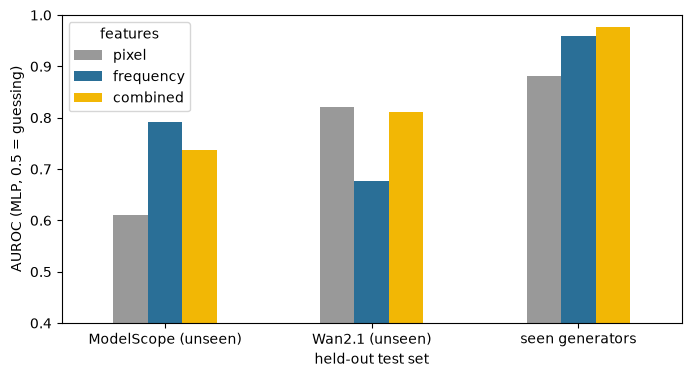

In [9]:
result = auroc_table([("pixel", "mlp_pixel"), ("frequency", "mlp_all"), ("combined", "mlp_fusion")])
print(result.to_string())
ax = result.plot.bar(rot=0, ylim=(0.4, 1), color=["#999999", "#2a6f97", "#f2b705"], figsize=(8, 4))
ax.set(xlabel="held-out test set", ylabel="AUROC (MLP, 0.5 = guessing)"); ax.legend(title="features");

## 6. Same numbers as the stored results?

In [10]:
stored = pd.read_csv(RESULTS / "test_metrics.csv")
stored = stored[stored.set == "seen_test"].set_index("model").auroc
print("seen generators, MLP:  live  vs  stored")
for feat_name, model_file in [("pixel", "mlp_pixel"), ("frequency", "mlp_all"), ("combined", "mlp_fusion")]:
    print(f"  {feat_name:10s} {result.loc['seen generators', feat_name]:.3f}  {stored[model_file]:.3f}")

seen generators, MLP:  live  vs  stored
  pixel      0.881  0.881
  frequency  0.960  0.960
  combined   0.976  0.976
